In [1]:
import os

# Redirect ALL cache writes away from home dir
# These are necessary to avoid [Errno 122] Disk quota exceeded: '/u/<username>/.cache/arviz/daily_warning.tmp'
os.environ["XDG_CACHE_HOME"] = "/scratch/users/yinya/.cache"
os.environ["ARVIZ_HOME"] = "/scratch/users/yinya/.cache/arviz"
os.makedirs("/scratch/users/yinya/.cache", exist_ok=True)
os.makedirs("/scratch/users/yinya/.cache/arviz", exist_ok=True)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import corner
import uproot
import pandas as pd
import subprocess

from torch.utils.data import Dataset, DataLoader, random_split

from python.transforms import *
from python.pmssm_dataset import *
from python.load_data import *

File opened successfully!
Available classes: {'susy;1': 'TTree'}
Imported Class: susy;1
Tree information: <TTree 'susy' (1536 branches) at 0x7f05d5644250>


In [3]:
# returns the serial number of the gpu with most free memory
def get_free_gpu():
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
        capture_output=True, text=True
    )
    free_mem = [int(x) for x in result.stdout.strip().split("\n")]
    best_gpu = free_mem.index(max(free_mem))
    print(f"Selected GPU {best_gpu} ({free_mem[best_gpu]} MiB free)")
    return best_gpu

In [4]:
# We are only doing analysis in this notebook so cpu is enough
device = "cpu"

### Data loading and preprocessing

In [5]:
parameters_standardized.shape

(9607, 12)

In [6]:
mo_omega_dataset = pMSSM_Dataset(parameters_standardized, mo_omega, device)

Visualize the data $d$ from an arbitrary sample of the `pMSSM_dataset`.

In [7]:
# Get first sample
signal, params = mo_omega_dataset[0]
print(signal)
print(params)

tensor([86.7000])
tensor([ 0.5485,  1.1125, -0.5387,  1.2056, -0.5841,  0.3705,  1.2141, -1.0644,
         0.1646,  0.4739,  0.3704, -0.2141])


### Split data into train and test dataset
Determine the number of training and test samples from a `train_fraction` and use the function `random_split()` to separate the data into a training and test dataset. Afterwards define the training and test dataloaders.

In [8]:
num_samples = len(mo_omega_dataset)
train_fraction = 0.8
num_train = int(round(train_fraction * num_samples))
num_test = num_samples - num_train
generator1 = torch.Generator().manual_seed(42)
train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test], generator=generator1)
# train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test])


In the current version (01.06.2026) there is a problem that the RNG seed for random split was not specified for toy models 1-5,
which means we cannot recover the same train test split for the models, and we might be using data for evaluation that was used in training sample.

### Conditional Normalizing Flow
We use the `glasflow` library. It is a wrapper for [`nflows`](https://github.com/bayesiains/nflows), which implements different flow types (e.g. autoregressive flows and coupling flows) and transforms (e.g. rational-quadratic splines).


In [9]:
from glasflow.nflows import distributions, flows

The entire flow model consists of a standard normal base distribution, followed by the flow transform.

In [10]:
transform = create_transform(num_flow_steps = 10,
                             param_dim = np.shape(parameters)[-1],
                             context_dim = np.shape(mo_omega)[-1], #np.shape(data) instead of data.shape to avoid error by one-dim array
                             base_transform_kwargs = {"base_transform_type": "rq-coupling"})

base_distribution = distributions.StandardNormal(shape=[parameters.shape[-1]])

model = flows.Flow(transform, base_distribution)
model = model.to(device)

### Load Weights into the Model

In [11]:
id_training = 6
weights_path = f"../checkpoints/training_{id_training}.pt"
# weights_path = f"../checkpoints/training_{id_training}_epoch_1000.pt"
model.load_state_dict(torch.load(weights_path))

/tmp/ipykernel_965634/2040455866.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(weights_path))


<All keys matched successfully>

### Evaluate the result and visualize posteriors

In [12]:
model = model.eval() #Is equivalent to just "model.eval()", but gets rid of the verbose log

#### Negative Log Likelihood

In [13]:
def compute_nll(dataset, model):
    """
    Works for mo_omega_dataset directly, or any Subset of it.
    No DataLoader required.
    """
    # Unwrap Subset → get indices into the parent dataset
    if isinstance(dataset, torch.utils.data.Subset):
        parent = dataset.dataset
        idx = dataset.indices
        parameters  = parent.parameters[idx]   # shape: (N, ...)
        observables = parent.observables[idx]  # shape: (N, ...)
    else:
        parameters  = dataset.parameters
        observables = dataset.observables

    with torch.no_grad():
        nll = -model.log_prob(parameters, observables).sum() / len(dataset)

    return nll.item()

In [14]:
# compute_nll(mo_omega_dataset, model)
compute_nll(train_dataset, model)

12.706029891967773

#### Choose data points randomly

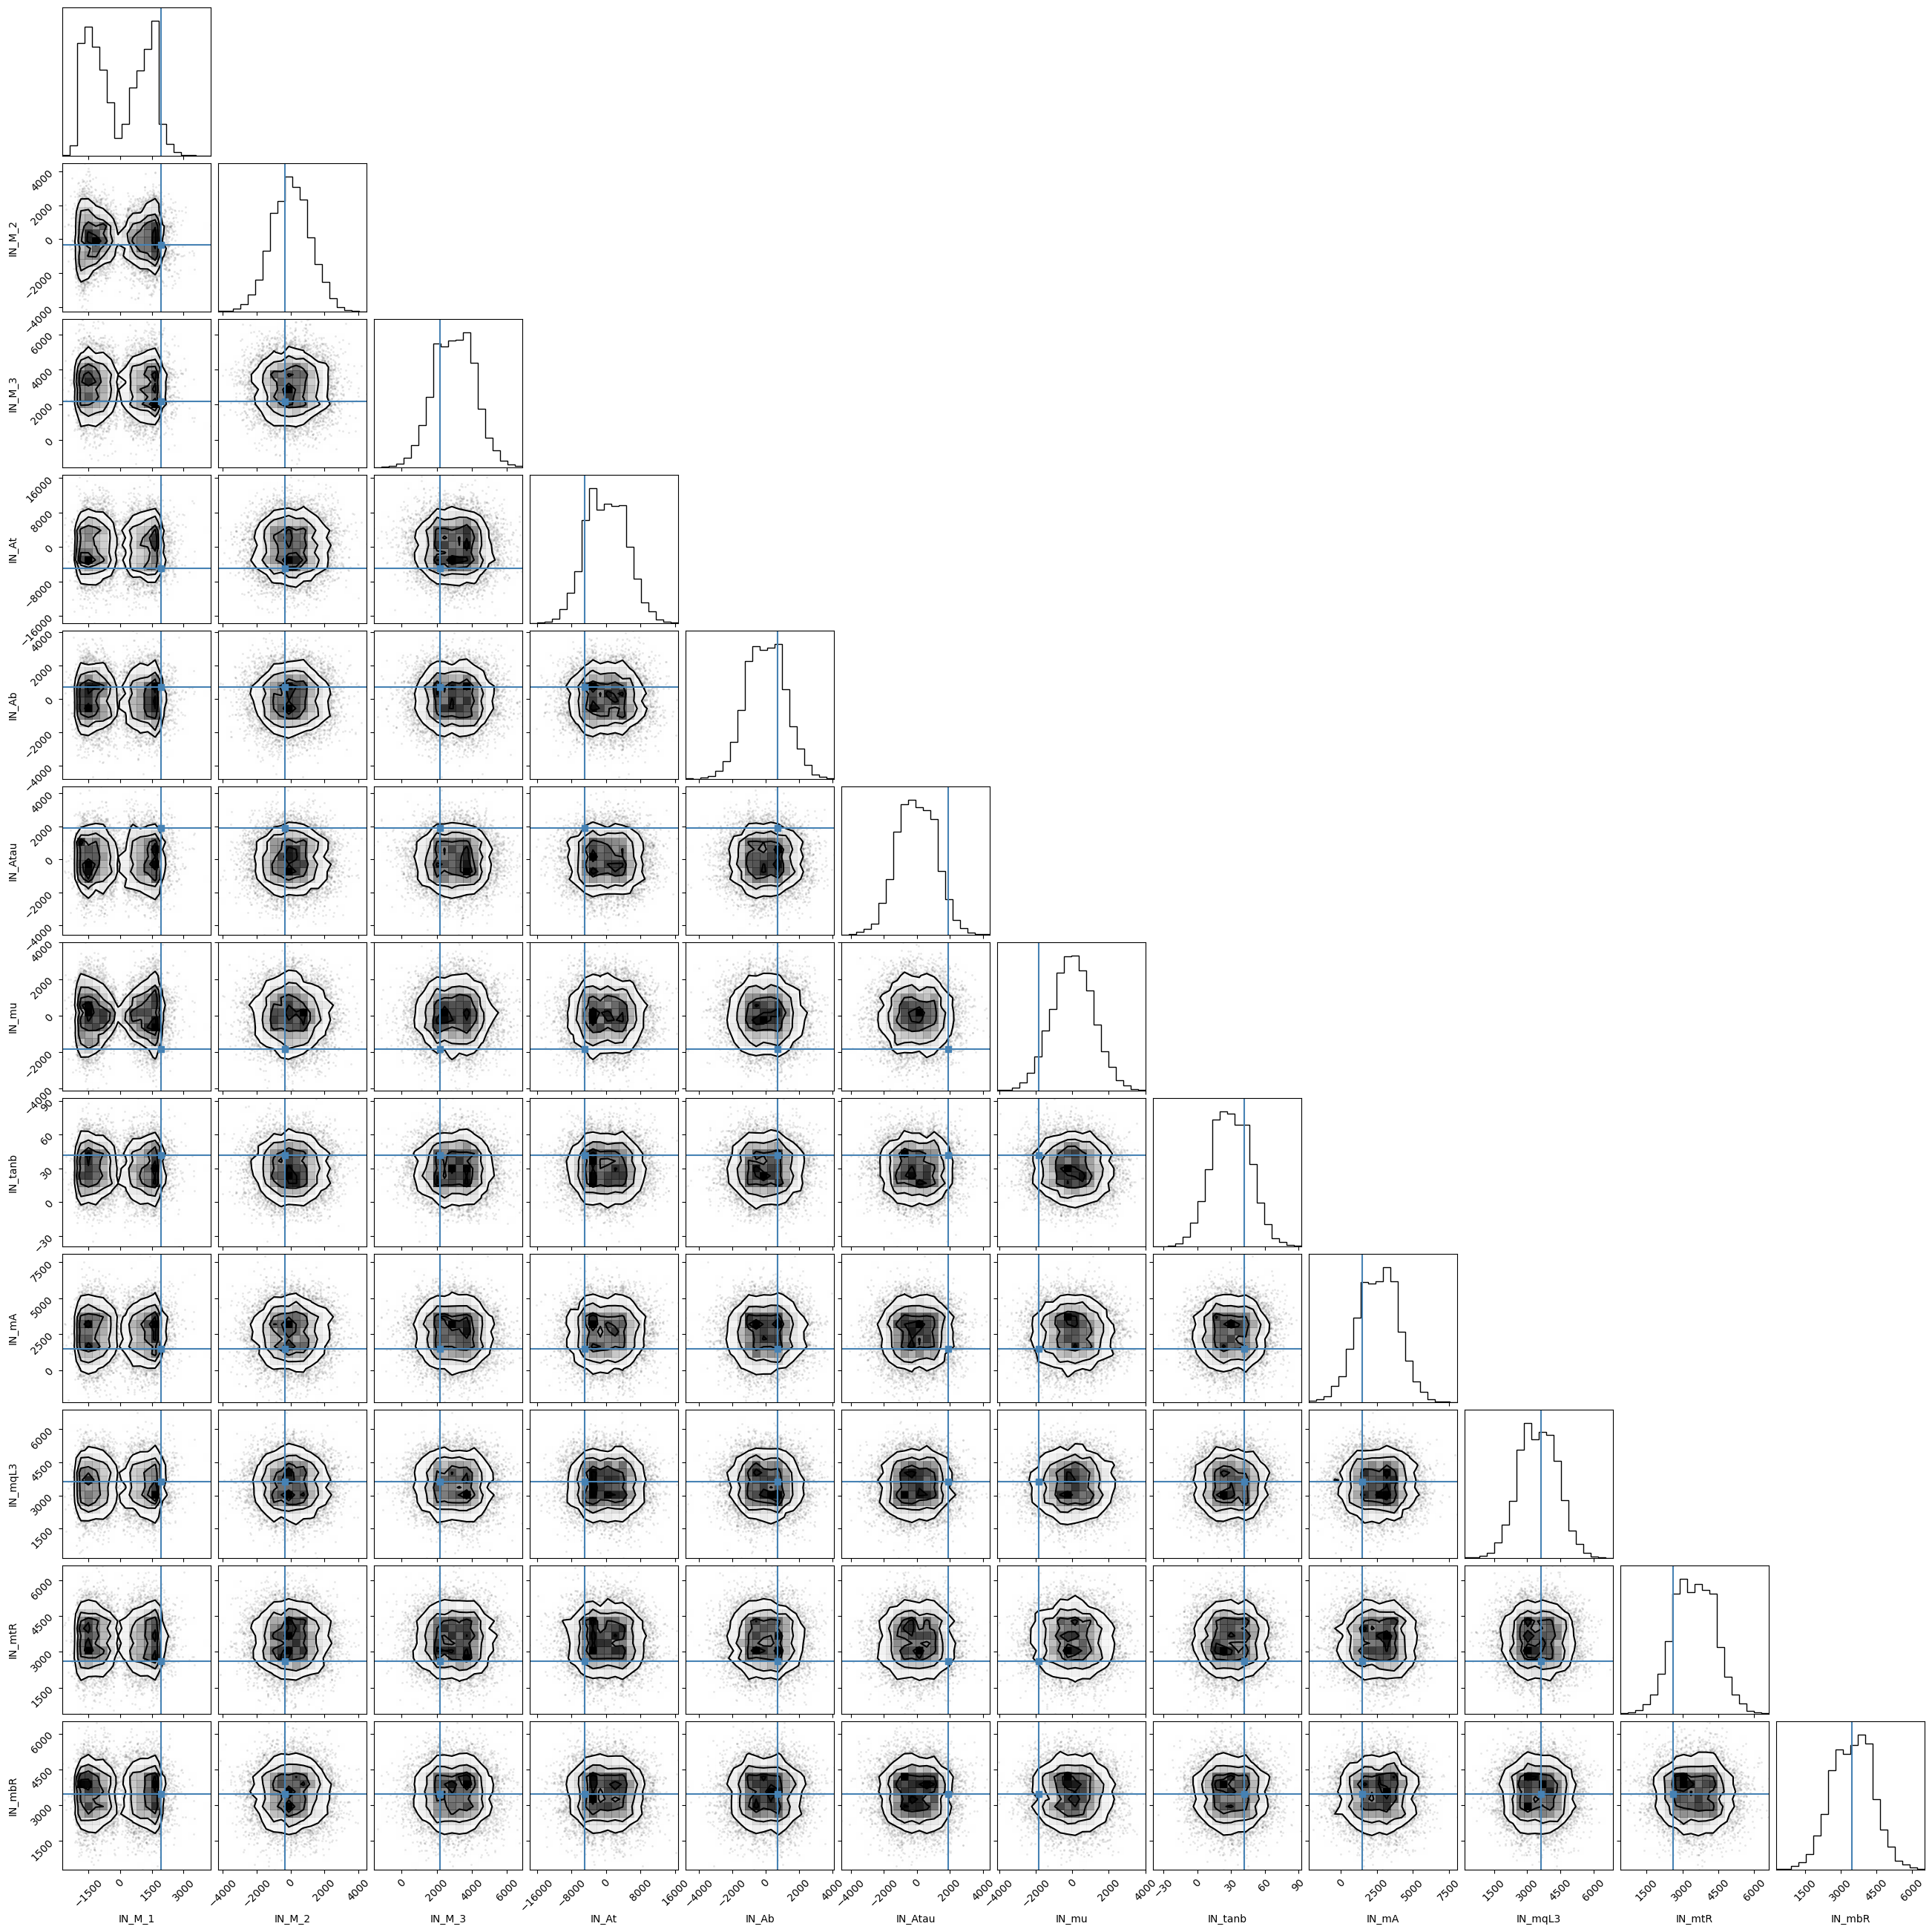

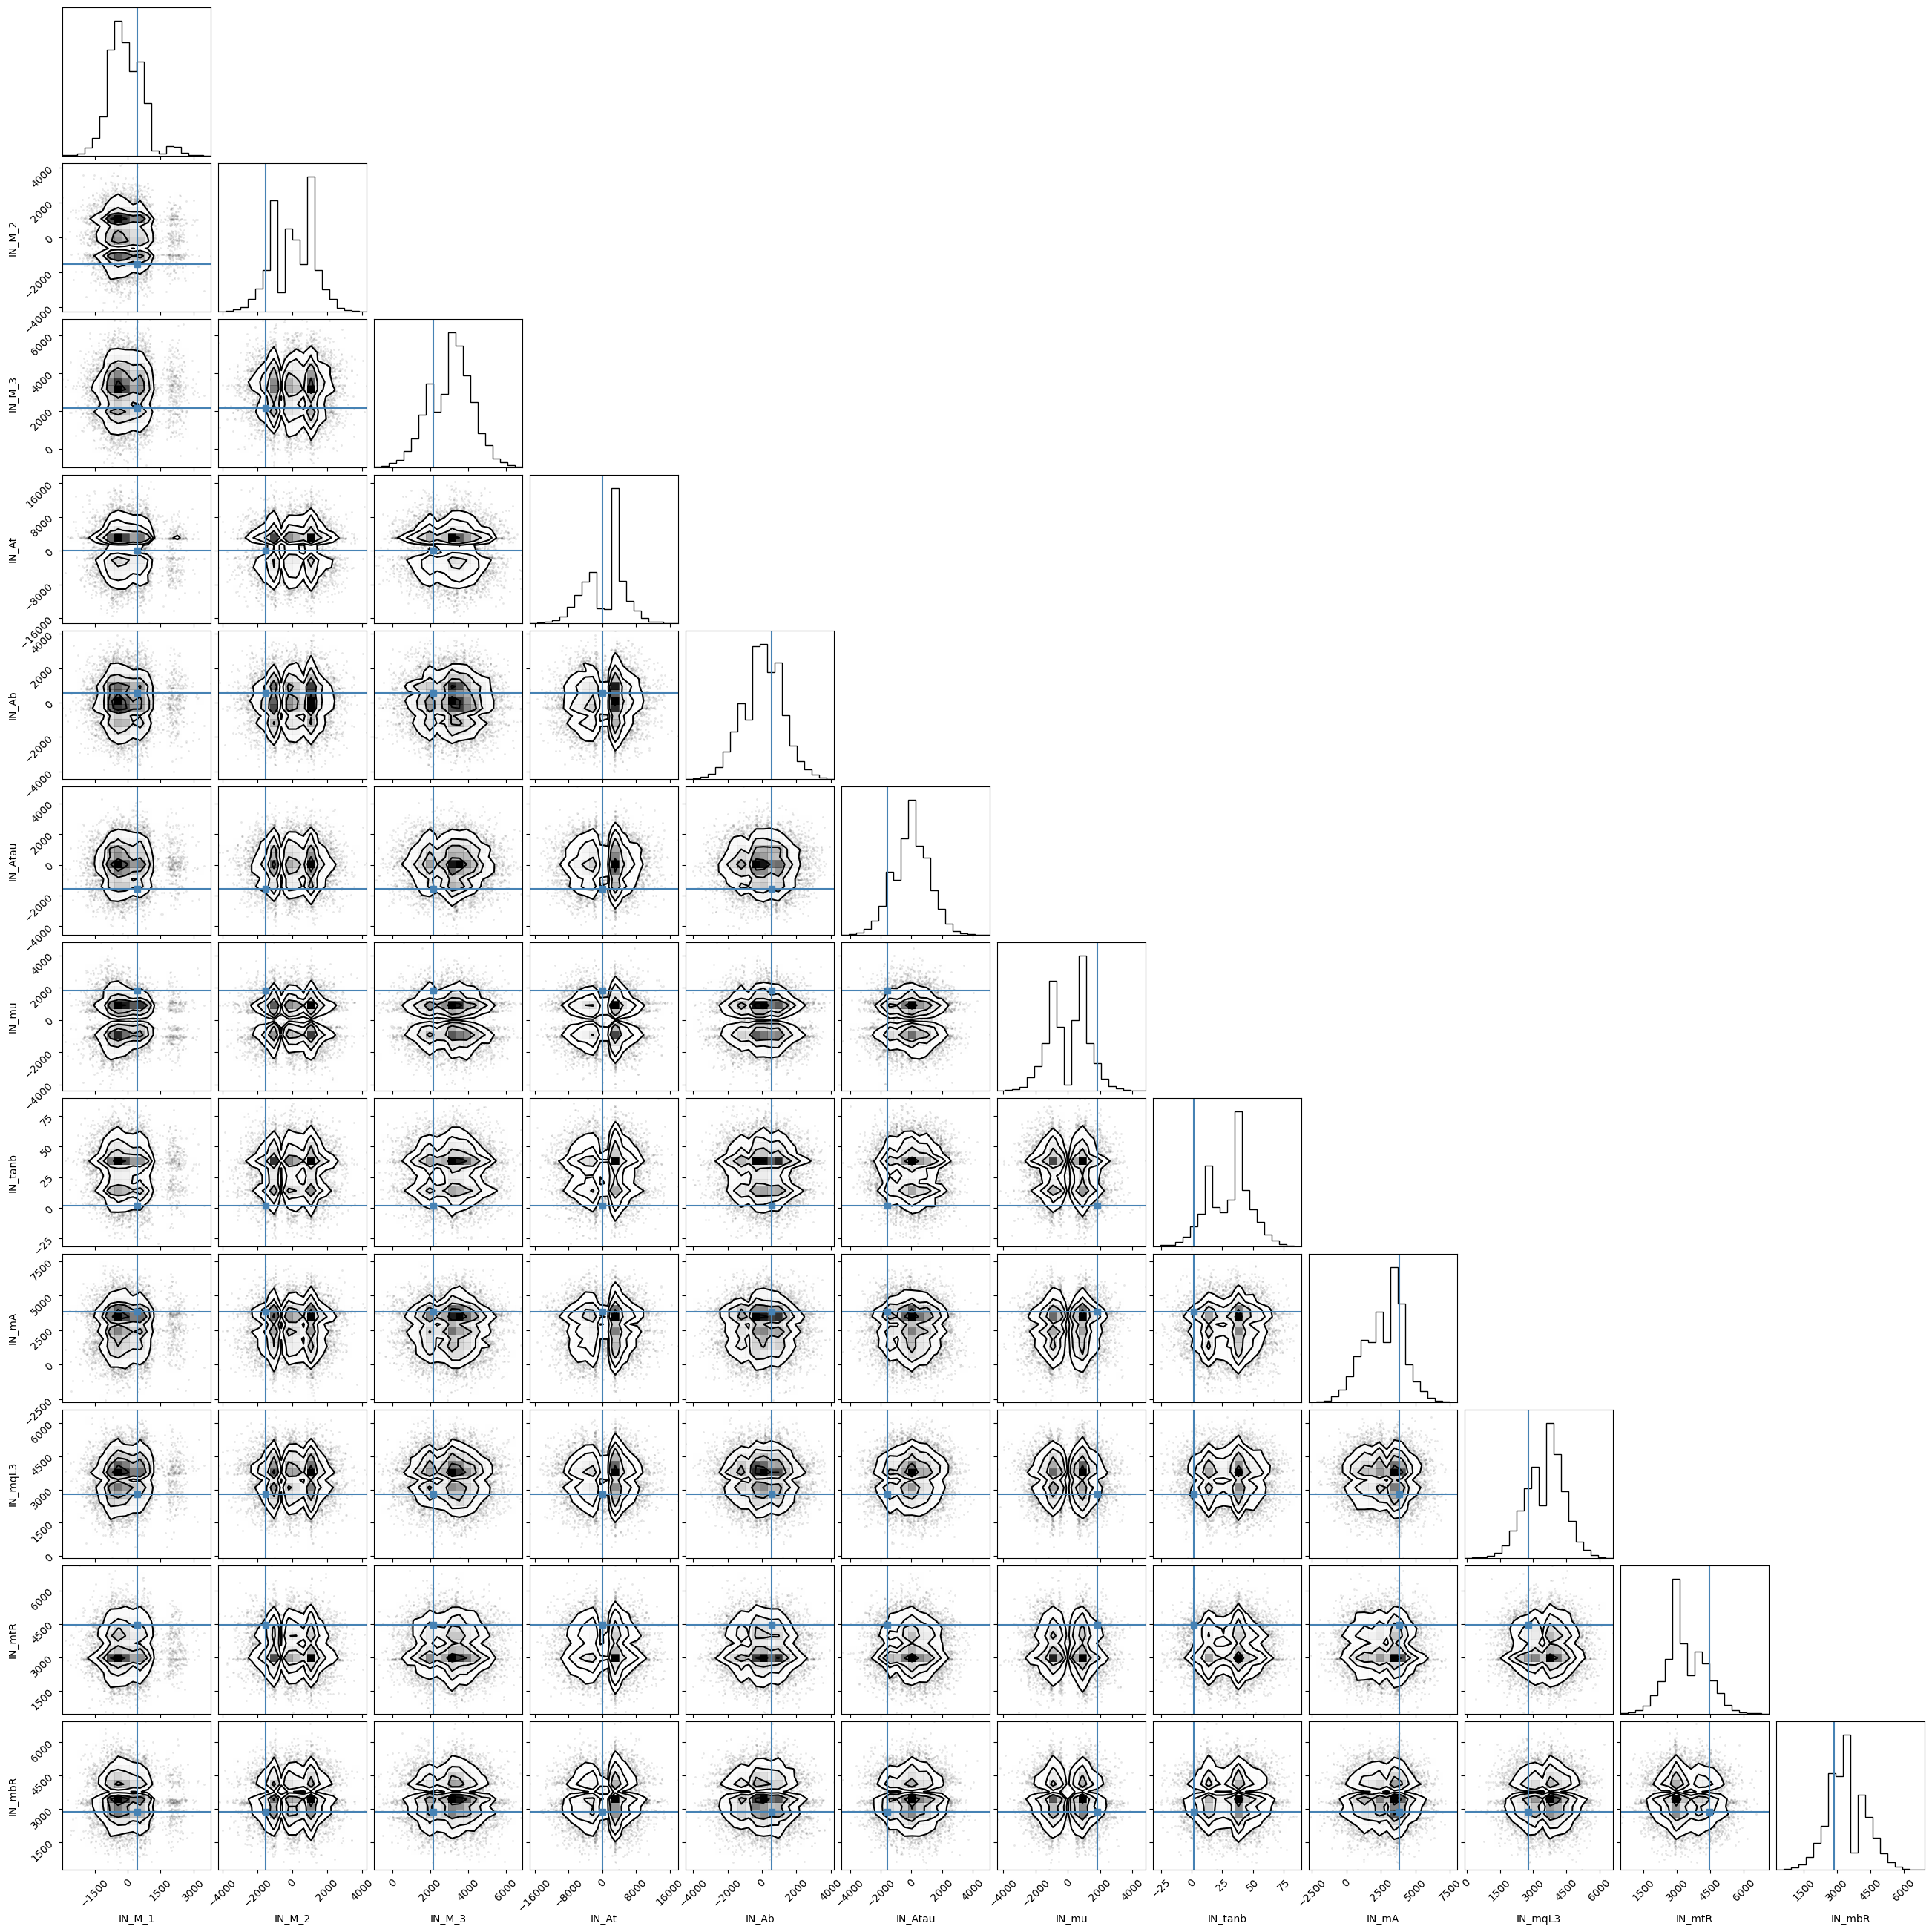

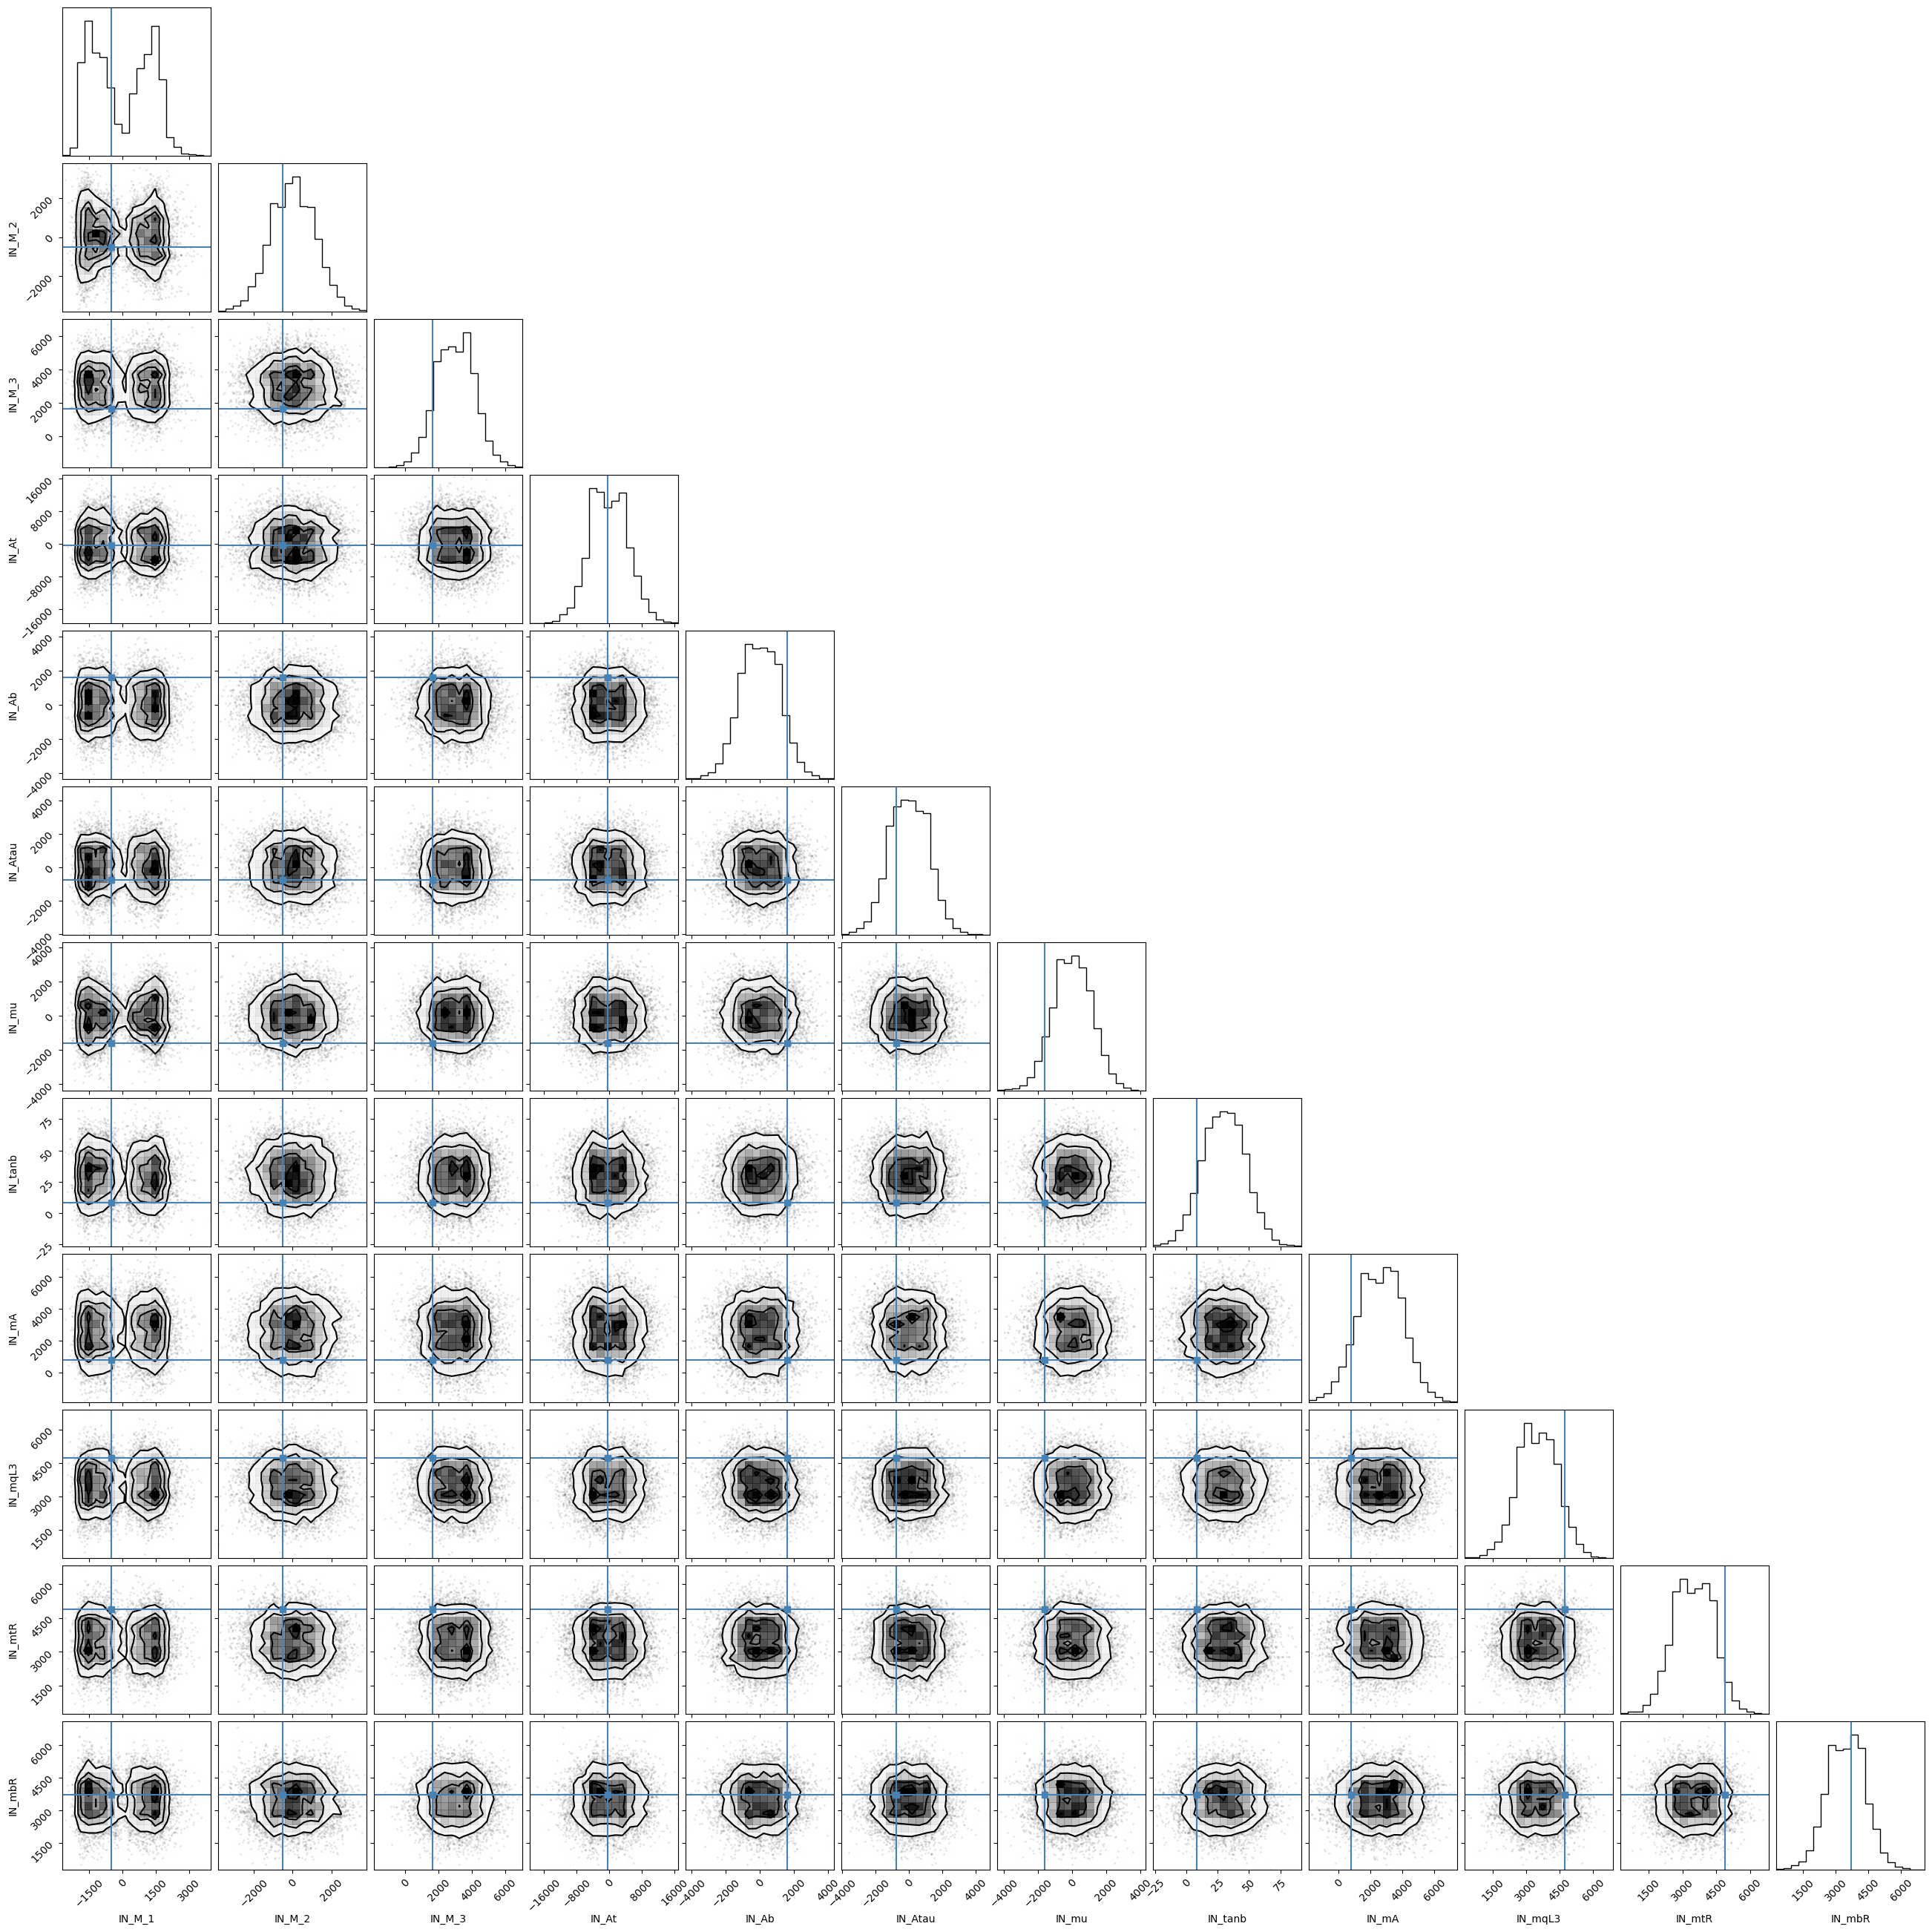

In [21]:
num_posteriors = 3
num_eval_samples = 10_000

# model = model.eval()

for n in range(num_posteriors):

    with torch.no_grad():
    
        test_x, test_y = test_dataset[n]
    
        # Sample the posterior
        test_x = test_x.expand(num_eval_samples, *test_x.shape)
        pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()
    
        # Undo the standardization
        pred_samples = parameters_std * pred_samples + parameters_mean
        truth = parameters_std * test_y.cpu().numpy() + parameters_mean
    
        # Plot
        corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
        plt.show()

#### Use data points closest to chosen observables

In [15]:
# test_dataset[0]
# import torch
# from torch.utils.data import DataLoader

def find_closest(dataset, target: float):
    """
    Returns the dataset item whose first tensor entry is closest to `target`.
    
    Args:
        dataset: A PyTorch Dataset where each item is (scalar_tensor, feature_tensor)
        target:  The float value to search for
    
    Returns:
        (best_item, best_idx, best_diff) – the matching item, its index, and the absolute difference
    """
    target_t = torch.tensor(target)
    best_idx  = None
    best_diff = float("inf")

    for idx in range(len(dataset)):
        item = dataset[idx]
        diff = (item[0] - target_t).abs().item()
        if diff < best_diff:
            best_diff = diff
            best_idx  = idx

    return dataset[best_idx], best_idx, best_diff

In [20]:
dataset_cl, idx_cl, diff_cl = find_closest(test_dataset, 10)
dataset_cl

(tensor([10.]),
 tensor([-0.6546,  0.7801, -1.4758,  0.4952, -0.1183,  1.5442, -0.8791, -0.1063,
          1.2031, -1.0123,  0.2811, -1.5030]))

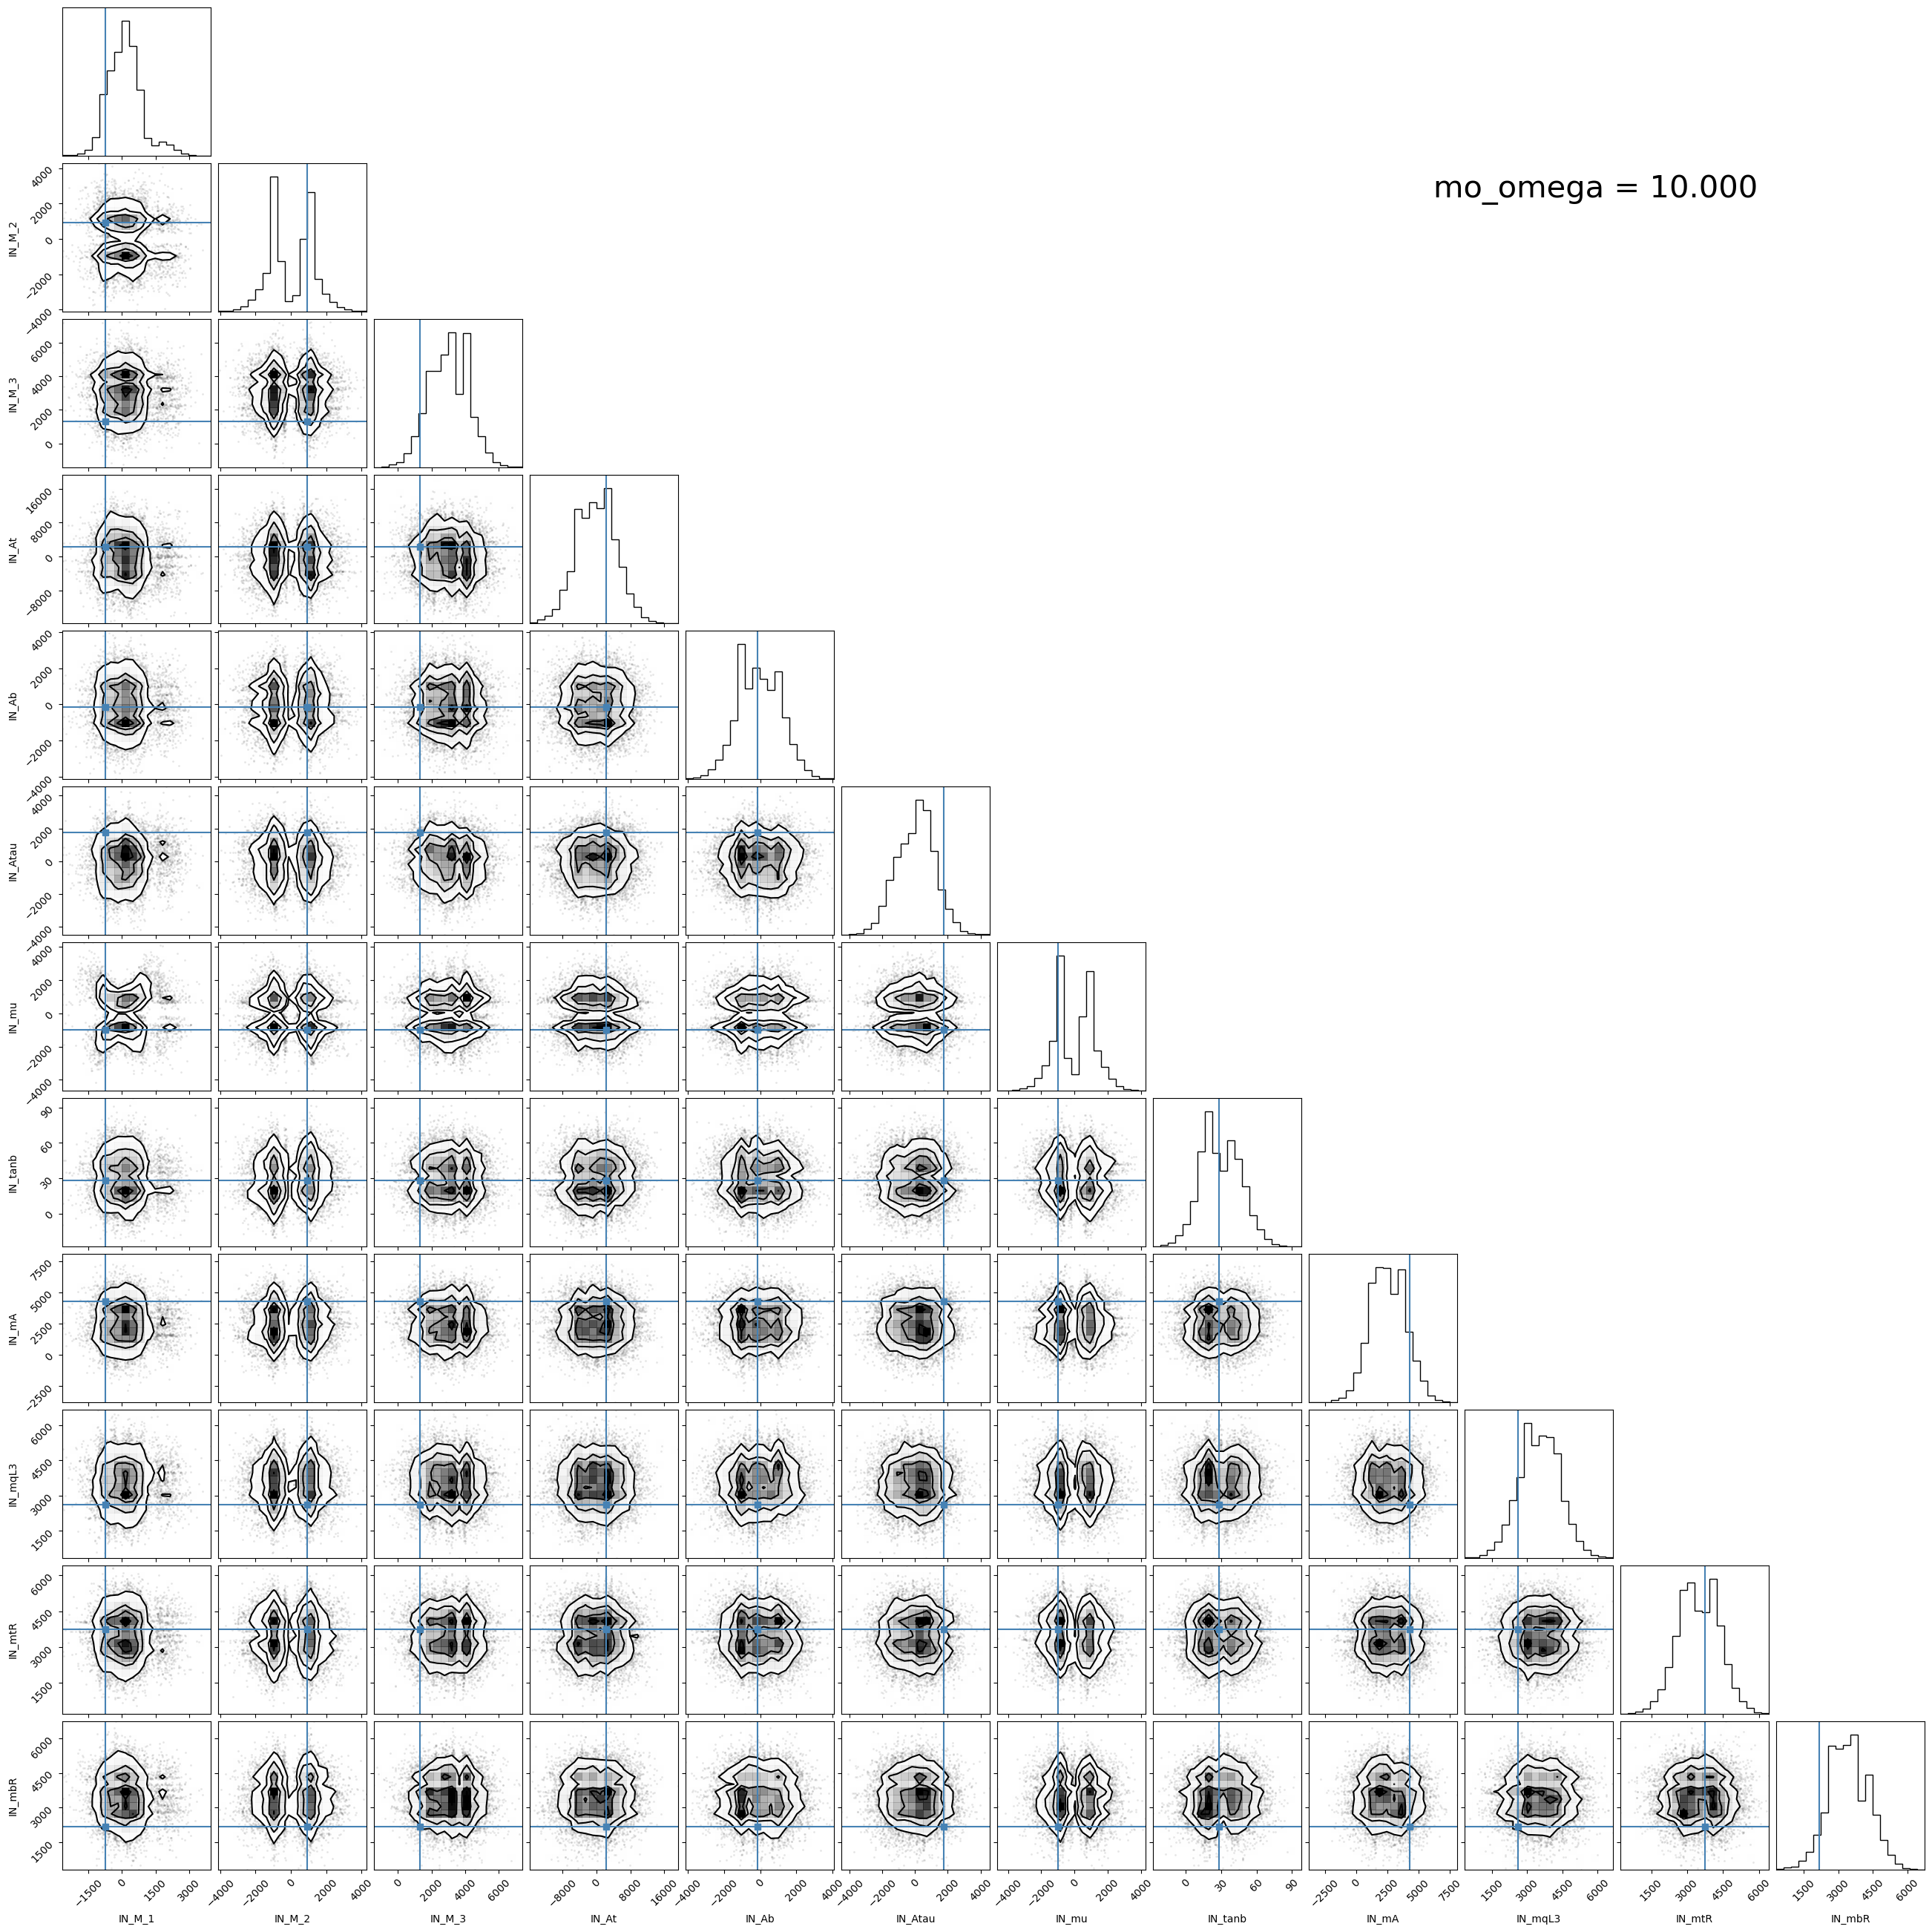

In [22]:
with torch.no_grad():

    test_x, test_y = test_dataset[idx_cl]

    # Sample the posterior
    test_x = test_x.expand(10000, *test_x.shape)
    pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()

    # Undo the standardization
    pred_samples = parameters_std * pred_samples + parameters_mean
    truth = parameters_std * test_y.cpu().numpy() + parameters_mean

    # Plot
    fig = corner.corner(
        pred_samples,
        truths=truth,
        labels=theory_param_nonconst
    )

    fig.text(
        0.9, 0.9,                 # x, y in figure coordinates
        f"mo_omega = {test_x[0].cpu().numpy()[0]:.3f}",
        ha="right",
        va="top",
        fontsize=30,
        # bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
    )

    plt.show()

#### Dynamic visualisation

In [25]:
from PIL import Image

input_folder = f"../figures/model_{id_training}"

if not os.path.exists(input_folder):
    os.makedirs(input_folder)

##### PNG Generation

In [ ]:
x_list = np.array([0.12, 1000])
ranges = np.outer(parameters_std, [-4,4]) + parameters_mean[:, None]

for x_value in x_list:
    with torch.no_grad():
        
        x_value = torch.as_tensor(x_value, device=device, dtype=torch.float32)

        if x_value.ndim == 0:
            x_value = x_value.unsqueeze(0)
        
        # Sample the posterior
        x_value = x_value.expand(10000, *x_value.shape)
        pred_samples = model.sample(1, x_value).squeeze(1).cpu().numpy()

        # Undo the standardization
        pred_samples = parameters_std * pred_samples + parameters_mean

        # Plot
        fig = corner.corner(
            pred_samples,
            labels=theory_param_nonconst,
            range=ranges
        )

        fig.text(
            0.9, 0.9,                 # x, y in figure coordinates
            f"mo_omega = {x_value[0].cpu().numpy()[0]:.3f}",
            ha="right",
            va="top",
            fontsize=30,
            # bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
        )

        plt.savefig(os.path.join(input_folder, f"model_{id_training}_mo_omega_{x_value[0].cpu().numpy()[0]:.3f}.png"))
        plt.close(fig)

Load Data

In [97]:
import glob
import re

def extract_value_one_path(path):
    # get the last number/float in the file names
    filename = os.path.basename(path)
    matches = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", filename)
    return float(matches[-1])

def extract_value(input_folder):
    paths = glob.glob(os.path.join(input_folder, "*.png"))
    values = np.array([extract_value_one_path(p) for p in paths])

    # sort
    order = np.argsort(values)
    values = values[order]
    paths = [paths[i] for i in order]

    return values, paths

##### GIF Generation

In [98]:
def pngs_to_gif(
    input_folder,
    output_gif="animation.gif",
    fps=10,
):
    """
    Convert PNG images in a folder into a GIF.

    Parameters
    ----------
    input_folder : str
        Folder containing PNG files.
    output_gif : str
        Output GIF filename.
    fps : float
        Frames per second.
    """

    _, paths = extract_value(input_folder)

    frames = [Image.open(f).convert("RGBA") for f in paths]

    duration_ms = int(1000 / fps)

    frames[0].save(
        output_gif,
        save_all=True,
        append_images=frames[1:],
        duration=duration_ms,
        loop=0,
        disposal=2,
    )

    print(f"GIF saved: {output_gif}")
    print(f"Frames: {len(frames)}")
    print(f"FPS: {fps}")
    
pngs_to_gif(
    input_folder=input_folder,
    output_gif=os.path.join(input_folder, f"model_{id_training}.gif"),
    fps=5,
)

GIF saved: ../figure_to_gif/model_6/model_6.gif
Frames: 40
FPS: 5


##### Interactive

In [99]:
from IPython.display import display
import ipywidgets as widgets


values, paths = extract_value(input_folder)

# ----------------------------
# exact-value lookup
# ----------------------------
def get_image(v):
    idx = np.where(values == v)[0][0]
    return paths[idx], v

# ----------------------------
# widget: ONLY allowed values
# ----------------------------
slider = widgets.SelectionSlider(
    options=[(f"{v:.3f}", v) for v in values],
    value=values[0],
    description="Omega",
    continuous_update=True
)

out = widgets.Output()

def update(change):
    with out:
        out.clear_output(wait=True)
        path, v = get_image(change["new"])
        print(f"Omega: {v}")
        display(Image.open(path))

slider.observe(update, names="value")

# initial display
update({"new": values[0]})

display(slider, out)

SelectionSlider(description='Omega', options=(('0.000', 0.0), ('0.025', 0.025), ('0.050', 0.05), ('0.075', 0.0…

Output()